# Multi-Target Prediction

We will use the [KIBA benchmark dataset](https://researchportal.helsinki.fi/en/datasets/kiba-a-benchmark-dataset-for-drug-target-prediction) of kinase inhibitor bioactivities as our example. KIBA is a large-scale drug-target binding affinity dataset originally containing 52,498 compounds and 467 kinase targets (246,088 affinity values). Each record is a drug-protein pair labeled with a continuous affinity score. We will load the dataset in PyTorch, explore its structure, and then implement three modeling approaches:


1. a basic matrix factorization via SVD
2. a two-branch neural network using learned embeddings
3. an extended two-branch network that also uses explicit drug/protein features to allow zero-shot prediction on new drugs or targets.

In [1]:
!pip install rdkit
!pip install pyTDC

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 13.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.2/154.2 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.4 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of pytdc to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.3/151.3 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 95.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.2/151.2 kB 9.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
from tdc.multi_pred import DTI
data = DTI(name = 'KIBA')
df = data.get_data() # contains columns: Drug, Target, Y, SMILES, Sequence

Downloading...
100%|██████████| 96.6M/96.6M [00:03<00:00, 25.0MiB/s]
Loading...
Done!


In [2]:
df

,Drug_ID,Drug,Target_ID,Target,Y
0,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O00141,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.10000
1,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O14920,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.10000
2,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,O15111,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.10000
3,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,P00533,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.10000
4,CHEMBL1087421,COc1cc2c(cc1Cl)C(c1ccc(Cl)c(Cl)c1)=NCC2,P04626,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.10000
...,...,...,...,...,...
117652,CHEMBL230654,CCCc1nc[nH]c1CNc1cc(Cl)c2ncc(C#N)c(Nc3ccc(F)c(...,Q13554,MATTVTCTRFTDEYQLYEDIGKGAFSVVRRCVKLCTGHEYAAKIIN...,10.49794
117653,CHEMBL230654,CCCc1nc[nH]c1CNc1cc(Cl)c2ncc(C#N)c(Nc3ccc(F)c(...,Q13555,MATTATCTRFTDDYQLFEELGKGAFSVVRRCVKKTSTQEYAAKIIN...,10.49794
117654,CHEMBL230654,CCCc1nc[nH]c1CNc1cc(Cl)c2ncc(C#N)c(Nc3ccc(F)c(...,Q13557,MASTTTCTRFTDEYQLFEELGKGAFSVVRRCMKIPTGQEYAAKIIN...,10.49794
117655,CHEMBL230654,CCCc1nc[nH]c1CNc1cc(Cl)c2ncc(C#N)c(Nc3ccc(F)c(...,Q16539,MSQERPTFYRQELNKTIWEVPERYQNLSPVGSGAYGSVCAAFDTKT...,10.49794


Our task is regression: given a drug-protein pair, predict the binding affinity score. As we can see right now the data is represented with every interaction as a row. We can also represent it as a matrix with missing values.

The following figure shows the different multi-target prediction settings, depending on the goal of the project.

In the first two sections we will look at Setting A, which is a a matrix-completion problem. Afterwards, we will look at settings where we want to predict the affinity for unseen drugs or proteins.

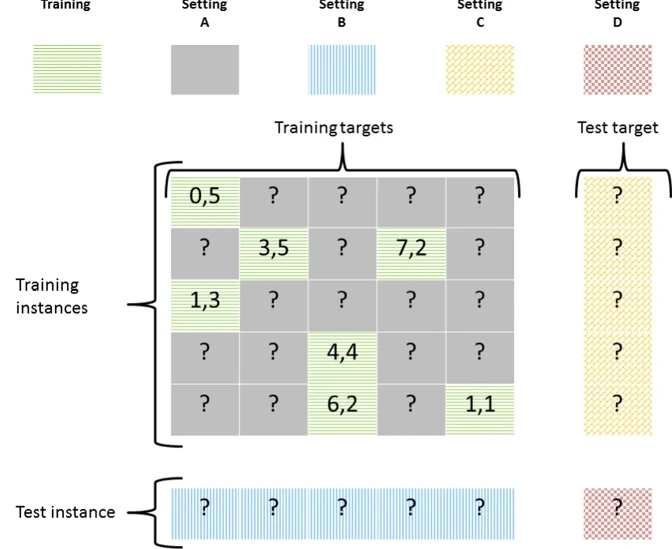

# 1. Matrix Factorization (Singular Value Decomposition)
A simple first approach is matrix factorization via SVD, which decomposes the interaction matrix into latent factors.

In [3]:
import pandas as pd
import numpy as np
from tdc.multi_pred import DTI

# Load data and get split from TDC
data = DTI(name = 'KIBA')
split = data.get_split()

train_df = split['train']
val_df = split['valid']
test_df = split['test']

Found local copy...
Loading...
Done!


Now we will build the matrix (only with the training data), missing values are filled with zeros.

In [4]:
# Build index mapping and interaction matrix using training data only
drugs = sorted(pd.concat([train_df['Drug_ID'], val_df["Drug_ID"], test_df['Drug_ID']]).unique())
prots = sorted(pd.concat([train_df['Target_ID'], val_df["Target_ID"], test_df['Target_ID']]).unique())
drug_to_idx = {d:i for i,d in enumerate(drugs)}
prot_to_idx = {p:i for i,p in enumerate(prots)}

M_train = np.zeros((len(drugs), len(prots)))
for _, row in train_df.iterrows():
    i = drug_to_idx[row['Drug_ID']]
    j = prot_to_idx[row['Target_ID']]
    M_train[i, j] = row['Y']  # affinity score

print("Training interaction matrix shape:", M_train.shape)

Training interaction matrix shape: (2068, 229)


And perform the SVD.

In [5]:
# Perform truncated SVD on the training matrix
from sklearn.utils.extmath import randomized_svd
k = 64  # latent dimension (chosen hyperparameter)
U, S, VT = randomized_svd(M_train, n_components=k, random_state=42)

print(f"SVD performed with k={k}")
print("Original matrix shape: ", M_train.shape)
print("U shape:", U.shape)
print("S shape:", S.shape)
print("VT shape:", VT.shape)

M_recon = U.dot(np.diag(S)).dot(VT)
print("Reconstructed matrix shape: ", M_recon.shape)


SVD performed with k=64
Original matrix shape:  (2068, 229)
U shape: (2068, 64)
S shape: (64,)
VT shape: (64, 229)
Reconstructed matrix shape:  (2068, 229)


In [6]:
# Evaluate on training set
mask = (M_train != 0)
mse = np.mean((M_recon[mask] - M_train[mask])**2)
print("train MSE: ", mse)

train MSE:  11.043778255971814


In [7]:
# Evaluate on test set

test_pred = []
test_true = []
for _, row in test_df.iterrows():
    i = drug_to_idx[row['Drug_ID']]
    j = prot_to_idx[row['Target_ID']]
    test_pred.append(M_recon[i, j])
    test_true.append(row['Y'])

test_pred = np.array(test_pred)
test_true = np.array(test_true)

mse = np.mean((test_pred - test_true)**2)

print(f"Test MSE (k={k}):", mse)

Test MSE (k=64): 77.64945781454135


# 2. Two-Branch Neural Network
A more flexible method is a two-branch neural network that embeds each drug and protein via learnable layers, then combines them to predict affinity.
Here we use simple embedding layers + MLP. Concretely, each drug index and protein index is mapped to a trainable embedding vector (size emb_dim), then concatenated and passed through an MLP to output one affinity score. The model is:

$$\hat{y}_{dp}=f(e_d,e_p),$$

where $\mathbf{e}_d$ and $\mathbf{e}_p$ are embedding vectors for drug $d$ and protein $p$. We then minimize MSE loss on known interactions.

**Exercise:** Implement the two-branch neural network model and train it on the training data. Evaluate its performance on the test set using MSE. Use embedding layers for the input of the different branches, and a simple MLP to merge the branches and to make the final prediction.

In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from tdc.multi_pred import DTI
import numpy as np

# Implement Two branch NN
class TwoBranchNN(nn.Module):
    def __init__(self, num_drugs, num_prots, emb_dim=64, hidden_dim=32):
        super().__init__()
        self.drug_emb = nn.Embedding(num_drugs, emb_dim)
        self.prot_emb = nn.Embedding(num_prots, emb_dim)

        self.drug_fc = nn.Linear(emb_dim, emb_dim)
        self.prot_fc = nn.Linear(emb_dim, emb_dim)

        # Layers after concatenation
        self.fc1 = nn.Linear(emb_dim * 2, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, d_idx, p_idx):
        d = self.drug_emb(d_idx)
        p = self.prot_emb(p_idx)
        d = F.relu(self.drug_fc(d))
        p = F.relu(self.prot_fc(p))

        # Concatenate latent vectors
        x = torch.cat([d, p], dim=1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x.squeeze()

In [26]:
# Prepare data tensors
train_d_idx = torch.LongTensor([drug_to_idx[d] for d in train_df['Drug_ID']])
train_p_idx = torch.LongTensor([prot_to_idx[p] for p in train_df['Target_ID']])
train_y = torch.FloatTensor(train_df['Y'].values)

val_d_idx = torch.LongTensor([drug_to_idx[d] for d in val_df['Drug_ID']])
val_p_idx = torch.LongTensor([prot_to_idx[p] for p in val_df['Target_ID']])
val_y = torch.FloatTensor(val_df['Y'].values)

test_d_idx = torch.LongTensor([drug_to_idx[d] for d in test_df['Drug_ID']])
test_p_idx = torch.LongTensor([prot_to_idx[p] for p in test_df['Target_ID']])
test_y = torch.FloatTensor(test_df['Y'].values)


train_ds = TensorDataset(train_d_idx, train_p_idx, train_y)
val_ds  = TensorDataset(val_d_idx,  val_p_idx,  val_y)
test_ds  = TensorDataset(test_d_idx,  test_p_idx,  test_y)

train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)
val_loader  = DataLoader(val_ds,  batch_size=1024)
test_loader  = DataLoader(test_ds,  batch_size=1024)

# Instantiate model, loss, optimizer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TwoBranchNN(len(drugs), len(prots), emb_dim=64, hidden_dim=64).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# Training loop
for epoch in range(50):
    model.train()
    for d_batch, p_batch, y_batch in train_loader:
        d_batch, p_batch, y_batch = d_batch.to(device), p_batch.to(device), y_batch.to(device)
        pred = model(d_batch, p_batch)
        loss = loss_fn(pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Evaluate on validation set
    model.eval()
    with torch.no_grad():
        val_pred = []
        val_true = []
        for d_batch, p_batch, y_batch in val_loader:
            d_batch, p_batch = d_batch.to(device), p_batch.to(device)
            out = model(d_batch, p_batch)
            val_pred.append(out.cpu())
            val_true.append(y_batch)
        val_pred = torch.cat(val_pred).numpy()
        val_true = torch.cat(val_true).numpy()
        mse = ((val_pred - val_true)**2).mean()
        print(f"Epoch {epoch+1}: validation MSE = {mse:.3f}")

# Final evaluation on test set
model.eval()
with torch.no_grad():
    test_pred = []
    test_true = []
    for d_batch, p_batch, y_batch in test_loader:
        d_batch, p_batch = d_batch.to(device), p_batch.to(device)
        out = model(d_batch, p_batch)
        test_pred.append(out.cpu())
        test_true.append(y_batch)
    test_pred = torch.cat(test_pred).numpy()
    test_true = torch.cat(test_true).numpy()
    test_mse = ((test_pred - test_true)**2).mean()
    print(f"\nFinal test MSE = {test_mse:.3f}")

Epoch 1: validation MSE = 2.266
Epoch 2: validation MSE = 1.223
Epoch 3: validation MSE = 1.154
Epoch 4: validation MSE = 1.146
Epoch 5: validation MSE = 1.154
Epoch 6: validation MSE = 1.157
Epoch 7: validation MSE = 1.180
Epoch 8: validation MSE = 1.195
Epoch 9: validation MSE = 1.211
Epoch 10: validation MSE = 1.205
Epoch 11: validation MSE = 1.213
Epoch 12: validation MSE = 1.237
Epoch 13: validation MSE = 1.233
Epoch 14: validation MSE = 1.257
Epoch 15: validation MSE = 1.255
Epoch 16: validation MSE = 1.236
Epoch 17: validation MSE = 1.235
Epoch 18: validation MSE = 1.252
Epoch 19: validation MSE = 1.267
Epoch 20: validation MSE = 1.268
Epoch 21: validation MSE = 1.240
Epoch 22: validation MSE = 1.244
Epoch 23: validation MSE = 1.237
Epoch 24: validation MSE = 1.247
Epoch 25: validation MSE = 1.244
Epoch 26: validation MSE = 1.247
Epoch 27: validation MSE = 1.243
Epoch 28: validation MSE = 1.229
Epoch 29: validation MSE = 1.239
Epoch 30: validation MSE = 1.235
Epoch 31: validatio

# 3. Extended Two-Branch Model with Features (Zero-Shot Prediction)

To generalize to new drugs or proteins (zero-shot prediction), we incorporate explicit features of compounds and proteins alongside embeddings. For example, we can compute a molecular fingerprint for each SMILES string, and a simple composition-based vector for each protein sequence.

These features can replace our ID embeddings or be used in addition to them, we will do the latter. The model now has two inputs per branch: (i) the ID embedding and (ii) the explicit feature vector. These are concatenated to produce the branch representation.

Explicitly, each drug’s SMILES is converted to a fixed-length fingerprint (e.g. 1024-bit Morgan fingerprint), and each protein sequence to a numeric feature (e.g. counts of amino acids). These allow the model to form a prediction even if the drug or protein was not seen during training (it still has features). Formally, incorporating features enables prediction on new drug/target combinations.

**Exercise:** Implement this extended two-branch model that uses both ID embeddings and explicit features for drugs and proteins. Train it on the training data and evaluate its performance on the test set using MSE. Test its ability to predict interactions involving new drugs not seen during training.

In [24]:
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
from tdc.multi_pred import DTI
import pandas as pd
from tqdm import tqdm
import random


data = DTI(name='KIBA')
split = data.get_split(method='cold_drug')  # drug-holdout split

train_df, val_df, test_df = split['train'], split['valid'], split['test']

drug_ids = sorted(pd.concat([train_df['Drug_ID'], val_df['Drug_ID'], test_df['Drug_ID']]).unique())
prot_ids = sorted(pd.concat([train_df['Target_ID'], val_df['Target_ID'], test_df['Target_ID']]).unique())

drug_to_idx = {d: i for i, d in enumerate(drug_ids)}
prot_to_idx = {p: i for i, p in enumerate(prot_ids)}

full_df = data.get_data()
drug_smiles_map = full_df.set_index('Drug_ID')['Drug'].to_dict()
prot_seq_map = full_df.set_index('Target_ID')['Target'].to_dict()

num_bits = 512
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

def morgan_fp(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.zeros(num_bits)
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=num_bits)
    arr = np.zeros((num_bits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

def aa_counts(seq):
    return np.array([seq.count(aa) for aa in amino_acids])

# Compute and cache features
drug_feat_map = {d: morgan_fp(drug_smiles_map[d]) for d in drug_ids}
prot_feat_map = {p: aa_counts(prot_seq_map[p]) for p in prot_ids}

# Convert to tensors
drug_feat_tensor = torch.FloatTensor([drug_feat_map[d] for d in drug_ids])
prot_feat_tensor = torch.FloatTensor([prot_feat_map[p] for p in prot_ids])


# Dataset construction

def make_tensor_dataset(df):
    d_idx = torch.LongTensor([drug_to_idx[d] for d in df['Drug_ID']])
    p_idx = torch.LongTensor([prot_to_idx[p] for p in df['Target_ID']])
    y = torch.FloatTensor(df['Y'].values)
    d_feat = drug_feat_tensor[d_idx]
    p_feat = prot_feat_tensor[p_idx]
    return TensorDataset(d_idx, p_idx, y, d_feat, p_feat)

train_ds = make_tensor_dataset(train_df)
val_ds   = make_tensor_dataset(val_df)
test_ds  = make_tensor_dataset(test_df)

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=256)
test_loader  = DataLoader(test_ds, batch_size=256)


# Model definition

class TwoBranchWithFeatures(nn.Module):
    def __init__(self, num_drugs, num_prots, emb_dim=64, feat_drug_dim=512, feat_prot_dim=20, hidden_dim=128):
        super().__init__()
        # ID embeddings
        self.drug_emb = nn.Embedding(num_drugs, emb_dim)
        self.prot_emb = nn.Embedding(num_prots, emb_dim)

        # Two-layer MLP per branch on concatenated [ID embedding | features]
        self.drug_mlp1 = nn.Linear(emb_dim + feat_drug_dim, hidden_dim)
        self.drug_mlp2 = nn.Linear(hidden_dim, hidden_dim)

        self.prot_mlp1 = nn.Linear(emb_dim + feat_prot_dim, hidden_dim)
        self.prot_mlp2 = nn.Linear(hidden_dim, hidden_dim)

        # Two-layer head after concatenating both branches
        self.post1 = nn.Linear(2 * hidden_dim, hidden_dim)
        self.post2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, 1)

    def forward(self, d_idx, p_idx, d_feat, p_feat):
        # Concatenate ID embeddings with raw features
        d = torch.cat([self.drug_emb(d_idx), d_feat], dim=-1)
        p = torch.cat([self.prot_emb(p_idx), p_feat], dim=-1)

        # Two linear layers per branch
        d = F.relu(self.drug_mlp1(d))
        d = F.relu(self.drug_mlp2(d))

        p = F.relu(self.prot_mlp1(p))
        p = F.relu(self.prot_mlp2(p))

        # Concatenate branches and pass through two more layers
        x = torch.cat([d, p], dim=-1)
        x = F.relu(self.post1(x))
        x = F.relu(self.post2(x))

        # Output
        x = self.out(x)
        return x.squeeze(-1)

# Training loop

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TwoBranchWithFeatures(len(drug_ids), len(prot_ids)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(1, 51):
    model.train()
    for d_idx, p_idx, y, d_feat, p_feat in tqdm(train_loader, desc=f"Epoch {epoch}"):
        d_idx, p_idx, y, d_feat, p_feat = d_idx.to(device), p_idx.to(device), y.to(device), d_feat.to(device), p_feat.to(device)
        pred = model(d_idx, p_idx, d_feat, p_feat)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Validation
    model.eval()
    with torch.no_grad():
        preds, targets = [], []
        for d_idx, p_idx, y, d_feat, p_feat in val_loader:
            d_idx, p_idx, d_feat, p_feat = d_idx.to(device), p_idx.to(device), d_feat.to(device), p_feat.to(device)
            out = model(d_idx, p_idx, d_feat, p_feat)
            preds.append(out.cpu())
            targets.append(y)
        preds = torch.cat(preds)
        targets = torch.cat(targets)
        val_mse = ((preds - targets) ** 2).mean().item()
    print(f"Epoch {epoch}: val MSE={val_mse:.4f}")



Found local copy...
Loading...
Done!
Epoch 1: 100%|██████████| 323/323 [00:06<00:00, 48.49it/s]


Epoch 1: val MSE=1.4016


Epoch 2: 100%|██████████| 323/323 [00:07<00:00, 43.97it/s]


Epoch 2: val MSE=1.4717


Epoch 3: 100%|██████████| 323/323 [00:07<00:00, 43.36it/s]


...

Epoch 48: val MSE=1.2243


Epoch 49: 100%|██████████| 323/323 [00:06<00:00, 51.49it/s]


Epoch 49: val MSE=1.1637


Epoch 50: 100%|██████████| 323/323 [00:07<00:00, 43.44it/s]


Epoch 50: val MSE=1.1619


In [18]:
# Final test evaluation

model.eval()
with torch.no_grad():
    preds, targets = [], []
    for d_idx, p_idx, y, d_feat, p_feat in test_loader:
        d_idx, p_idx, d_feat, p_feat = d_idx.to(device), p_idx.to(device), d_feat.to(device), p_feat.to(device)
        out = model(d_idx, p_idx, d_feat, p_feat)
        preds.append(out.cpu())
        targets.append(y)
    preds = torch.cat(preds)
    targets = torch.cat(targets)
    test_mse = ((preds - targets) ** 2).mean().item()
print(f"\nFinal test MSE (drug-holdout) = {test_mse:.3f}")


Final test MSE (drug-holdout) = 1.185
